# 支持向量机

### 问题

前面几个模型里,能把两类分开的线往往不止一条,逻辑回归挑一条,树挑一堆方块。SVM 挑的是**间隔最大**的那条:让分界线离两边最近的点都尽量远。

最近的那些点叫支持向量,只有它们决定分界线,其他点删掉不影响结果。实际数据里两类经常有重叠,所以允许一点点越界,用 C 控制松紧:

- C 大,几乎不许错,间隔窄,容易过拟合;
- C 小,允许错,间隔宽,更稳。

线性分不开的时候就上核函数。RBF 核相当于把每个样本映射到无穷维,再用一个 gamma 控制"影响半径":

$$K(x_i,x_j)=\exp(-\gamma\|x_i-x_j\|^2)$$

gamma 大,每个点只影响附近一小片;gamma 小,影响范围大,边界就更平滑。

## 1. 造一组线性可分的数据

两类点分别从 (0, 0) 和 (3, 3) 附近生成,标准差 0.6,中间留了明显的空隙。

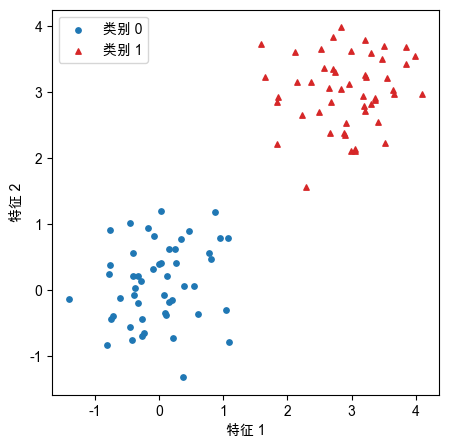

In [1]:
import warnings
import numpy as np
import matplotlib.pyplot as plt

# 本机 numpy 2.0 会对 matmul 误报浮点警告,结果是对的
warnings.filterwarnings("ignore", message=".*in matmul")

# 中文和负号
plt.rcParams["font.sans-serif"] = ["Arial Unicode MS"]
plt.rcParams["axes.unicode_minus"] = False

rng = np.random.default_rng(0)
X = np.r_[rng.normal([0, 0], 0.6, (50, 2)), rng.normal([3, 3], 0.6, (50, 2))]
y = np.r_[np.zeros(50), np.ones(50)]

fig, ax = plt.subplots(figsize=(5, 5))
ax.scatter(X[y == 0, 0], X[y == 0, 1], s=15, label="类别 0")
ax.scatter(X[y == 1, 0], X[y == 1, 1], s=15, c="tab:red", marker="^", label="类别 1")
ax.set_xlabel("特征 1")
ax.set_ylabel("特征 2")
ax.legend()
plt.show()

## 2. 最大间隔

先用线性核,C=1。

In [2]:
from sklearn.svm import SVC

svm = SVC(kernel="linear", C=1).fit(X, y)

print("w", svm.coef_[0].round(3), "b", round(svm.intercept_[0], 3))
print("间隔宽度", round(2 / np.linalg.norm(svm.coef_), 3))
print("支持向量", len(svm.support_), "个")
print("训练集准确率", svm.score(X, y))

w [1.147 0.797] b -2.869
间隔宽度 1.432
支持向量 4 个
训练集准确率 1.0


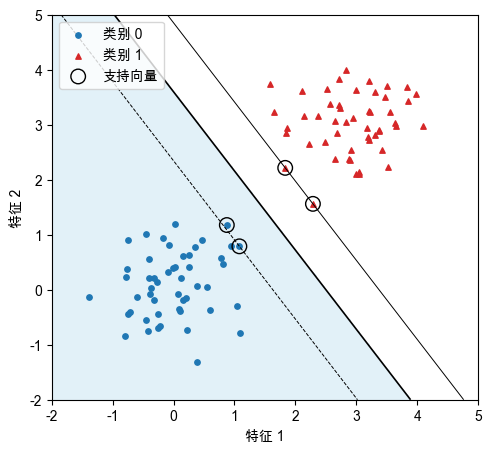

In [3]:
xx, yy = np.meshgrid(np.linspace(-2, 5, 200), np.linspace(-2, 5, 200))

fig, ax = plt.subplots(figsize=(5.5, 5))
D = svm.decision_function(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)

ax.contourf(xx, yy, D > 0, levels=[-0.5, 0.5], colors=["#8ecae6", "#e07a5f"], alpha=0.25)
ax.contour(xx, yy, D, levels=[-1, 0, 1], colors="black", linewidths=[0.7, 1.2, 0.7])

ax.scatter(X[y == 0, 0], X[y == 0, 1], s=15, label="类别 0")
ax.scatter(X[y == 1, 0], X[y == 1, 1], s=15, c="tab:red", marker="^", label="类别 1")
ax.scatter(svm.support_vectors_[:, 0], svm.support_vectors_[:, 1],
           s=110, facecolors="none", edgecolors="black", label="支持向量")

ax.set_xlabel("特征 1")
ax.set_ylabel("特征 2")
ax.legend(loc="upper left")
plt.show()

两条虚线之间的宽度就是间隔,压在虚线或越过虚线的点被圈了出来,一共 4 个。其余 96 个点对结果没有任何影响:

把它们删掉,只用这 4 个点重新训练,分界线几乎一模一样。

In [4]:
only_sv = SVC(kernel="linear", C=1).fit(X[svm.support_], y[svm.support_])

print("只保留支持向量重训:", only_sv.coef_[0].round(3))
print("和全量训练的差:", np.abs(only_sv.coef_ - svm.coef_).max().round(5))

只保留支持向量重训: [1.146 0.797]
和全量训练的差: 0.0003


差在 0.0003 这个量级,来自 sklearn 的数值容差。这就是支持向量这个名字的来历:模型完全由少数几个关键点决定。

## 3. C 控制松紧

In [5]:
for C in [0.05, 1, 100]:
    m = SVC(kernel="linear", C=C).fit(X, y)
    margin = 2 / np.linalg.norm(m.coef_)
    print(f"C={C:<6} 支持向量 {len(m.support_):<3} 间隔 {margin:.2f} 训练准确率 {m.score(X, y):.3f}")

C=0.05   支持向量 15  间隔 2.66 训练准确率 1.000
C=1      支持向量 4   间隔 1.43 训练准确率 1.000
C=100    支持向量 3   间隔 1.38 训练准确率 1.000


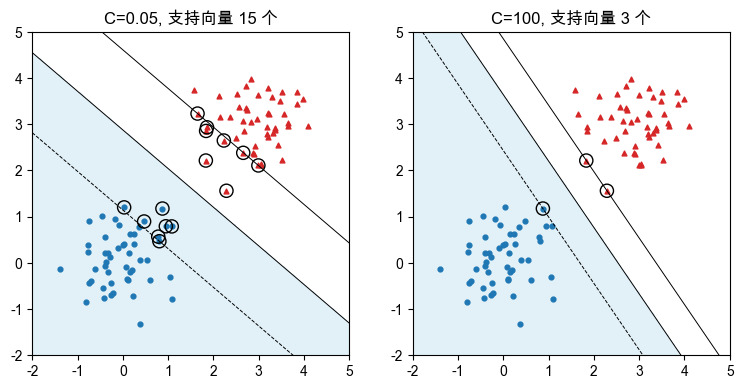

In [6]:
fig, axs = plt.subplots(1, 2, figsize=(9, 4.2))

for ax, C in zip(axs, [0.05, 100]):
    m = SVC(kernel="linear", C=C).fit(X, y)
    D = m.decision_function(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    ax.contourf(xx, yy, D > 0, levels=[-0.5, 0.5], colors=["#8ecae6", "#e07a5f"], alpha=0.25)
    ax.contour(xx, yy, D, levels=[-1, 0, 1], colors="black", linewidths=0.7)
    ax.scatter(X[y == 0, 0], X[y == 0, 1], s=12, c="tab:blue")
    ax.scatter(X[y == 1, 0], X[y == 1, 1], s=12, c="tab:red", marker="^")
    ax.scatter(m.support_vectors_[:, 0], m.support_vectors_[:, 1],
               s=90, facecolors="none", edgecolors="black")
    ax.set_title(f"C={C}, 支持向量 {len(m.support_)} 个")

plt.show()

C=0.05 时有 15 个支持向量,间隔宽到 2.66,边上的点被默许越界;C=100 时只剩 3 个,间隔压缩到 1.38,模型死抠每一个点。

在这份干净数据上两者训练准确率都是 1.0,差别要等数据有噪声才看得出来:这时 C 小反而是好事。

## 4. 线性核不够用

换成月牙形数据,两类怎么画直线都分不开。

In [7]:
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split, cross_val_score

X_m, y_m = make_moons(n_samples=600, noise=0.3, random_state=0)
X_m_train, X_m_test, y_m_train, y_m_test = train_test_split(
    X_m, y_m, test_size=0.3, random_state=0, stratify=y_m)

for kernel in ["linear", "poly", "rbf"]:
    s = cross_val_score(SVC(kernel=kernel), X_m, y_m, cv=5).mean()
    print(f"{kernel:<7} CV {s:.4f}")

linear  CV 0.8650
poly    CV 0.8533
rbf     CV 0.9033


线性核 0.865 就到顶了,多项式核 0.853 也没好到哪去,换成 RBF 直接到 0.903。

核函数的作用不是把数据真的搬到高维再算,而是用核函数直接算出高维空间里的内积,计算量还是原来的量级。

## 5. RBF 的 gamma

gamma 决定每个样本的影响范围,是最难调的一个参数。

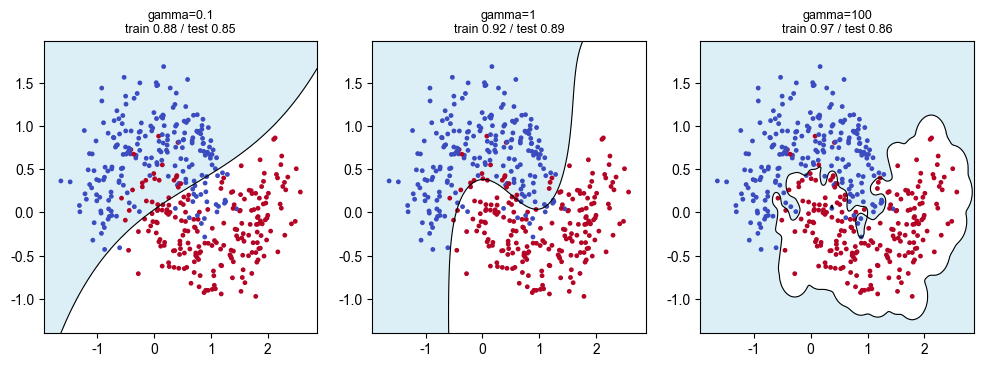

In [8]:
xx_m, yy_m = np.meshgrid(np.linspace(X_m[:, 0].min() - 0.3, X_m[:, 0].max() + 0.3, 250),
                         np.linspace(X_m[:, 1].min() - 0.3, X_m[:, 1].max() + 0.3, 250))
grid_m = np.c_[xx_m.ravel(), yy_m.ravel()]

fig, axs = plt.subplots(1, 3, figsize=(12, 3.8))

for ax, g in zip(axs, [0.1, 1, 100]):
    m = SVC(kernel="rbf", gamma=g).fit(X_m_train, y_m_train)
    D = m.decision_function(grid_m).reshape(xx_m.shape)
    ax.contourf(xx_m, yy_m, D > 0, levels=[-0.5, 0.5], colors=["#8ecae6", "#e07a5f"], alpha=0.3)
    ax.contour(xx_m, yy_m, D, levels=[0], colors="black", linewidths=0.8)
    ax.scatter(X_m_train[:, 0], X_m_train[:, 1], c=y_m_train, s=6, cmap="coolwarm")
    ax.set_title(f"gamma={g}\ntrain {m.score(X_m_train, y_m_train):.2f} / test {m.score(X_m_test, y_m_test):.2f}",
                 fontsize=9)

plt.show()

gamma=0.1 的边界很平,一条大弧线扫过去,弯不过月牙的形状,训练集只到 0.88;gamma=1 能顺着月牙弯,测试集 0.889 最好;gamma=100 的边界贴着训练点转,训练集 0.971,测试集掉到 0.856。

这和树变深是一个道理:模型的灵活度上去了,就容易把噪声当规律。

## 6. 特征缩放

SVM 靠距离算核,量纲大的特征会直接主导结果。拿乳腺癌数据比一下就知道了。

In [9]:
from sklearn.datasets import load_breast_cancer
from sklearn.preprocessing import StandardScaler

X_c, y_c = load_breast_cancer(return_X_y=True)
X_c_s = StandardScaler().fit_transform(X_c)

print("原始尺度 CV:", round(cross_val_score(SVC(kernel="rbf"), X_c, y_c, cv=5).mean(), 4))
print("标准化后 CV:", round(cross_val_score(SVC(kernel="rbf"), X_c_s, y_c, cv=5).mean(), 4))
print("线性核标准化 CV:", round(cross_val_score(SVC(kernel="linear"), X_c_s, y_c, cv=5).mean(), 4))

原始尺度 CV: 0.9122
标准化后 CV: 0.9736
线性核标准化 CV: 0.9701


不标准化 0.9122,标准化 0.9736,差了 6 个点。乳腺癌数据里面积、周长是几百,平滑度是零点零几,RBF 的距离几乎全被大数值特征占了。

这一条对所有基于距离的模型都成立,KNN、K-Means 后面还要再遇到一次。

## 7. 多分类

In [10]:
from sklearn.datasets import load_iris

X_i, y_i = load_iris(return_X_y=True)
multi = SVC(kernel="rbf").fit(X_i, y_i)

print("CV", round(cross_val_score(SVC(kernel="rbf"), X_i, y_i, cv=5).mean(), 4))
print("前 5 个预测:", multi.predict(X_i[:5]))
print("真实标签  :", y_i[:5])

CV 0.9667
前 5 个预测: [0 0 0 0 0]
真实标签  : [0 0 0 0 0]


SVM 本身只能做二分类。三个类别时 sklearn 用的是 one-vs-one:每两类之间训一个分类器,3 类就是 3 个,预测时投票。`decision_function_shape="ovr"` 只是把投票结果换算成 ovr 形状的输出,训练方式没变。

类别多了 OvO 需要训 k(k-1)/2 个模型,比 OvR 的 k 个多,但每个模型只用到两类数据。

## 8. 小结

- 间隔由支持向量决定,模型只跟少数关键点有关;
- C 控制软硬:C 小容忍越界,间隔宽;C 大逼得更紧,容易过拟合;
- 线性核搞不定的弯弯绕绕交给 RBF,gamma 决定边界能弯到什么程度;
- 一定先标准化,不然核函数算出来的距离会被大数值特征垄断;
- 多分类是 OvO 拼出来的,训练时间随类别数平方增长;
- 数据量大时 SVC 会慢得没法用,得换 `LinearSVC` 或 `SGDClassifier`。